# XGBoost con features geoespaciales

**Escenario:** geo (variables base + `distancia_*` + `cluster_zona`).

Se reutiliza `learning_rate=0.1`, el mejor valor encontrado en la baseline, y el mismo split/semilla. XGBoost requiere etiquetas enteras: se usan `codificar_y` y `decodificar_y` de `src/model_ordinal.py`.

- Entrada: `data/processed/airprice_features.csv`
- Salidas: `reports/xgboost_features_metricas.csv`, importancia y matriz de confusión.

In [2]:
import sys
sys.path.append('../..')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

from src.model_features import (
    PARAMS_BASE,
    construir_xgb_features,
    evaluar_modelo_ordinal,
    importancia_variables,
    metricas_a_fila,
)
from src.model_ordinal import codificar_y, decodificar_y
from src.preprocessing_features import FEATURES_PATH, preparar_dataset_features
from src.utils import (
    CLASES,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    fijar_semilla,
    guardar_modelo,
    split_estratificado,
)

sns.set_theme(style='whitegrid')
fijar_semilla(SEED)
print('Semilla:', SEED)

Semilla: 42


In [1]:
print(2+2)

4


In [3]:
df = preparar_dataset_features(cargar_dataset(FEATURES_PATH))
print('Filas:', df.shape[0], 'Columnas:', df.shape[1])

X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df,
    target='price_range',
    excluir=['price_clean', 'id'],
    seed=SEED,
)
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

y_train_enc = codificar_y(y_train)
y_val_enc = codificar_y(y_val)
y_test_enc = codificar_y(y_test)
print('Clases codificadas:', sorted(set(y_train_enc)))

Filas: 61617 Columnas: 29
Train: (43131, 28) Val: (9243, 28) Test: (9243, 28)
Clases codificadas: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [4]:
params = dict(PARAMS_BASE['xgboost'])
print('Hiperparámetros baseline:', params)

modelo = construir_xgb_features(X_train, **params)
modelo.fit(X_train, y_train_enc)

pred_val = decodificar_y(modelo.predict(X_val))
met_val = evaluar_modelo_ordinal(y_val, pred_val)
print({k: round(v, 4) for k, v in met_val.items() if k != 'matriz_confusion'})

Hiperparámetros baseline: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 6}
{'accuracy': 0.6782, 'balanced_accuracy': 0.6779, 'f1_macro': 0.6762, 'f1_weighted': 0.6765, 'accuracy_adjacent': 0.968, 'mae_ordinal': 0.3579, 'qwk': 0.8268}


{'accuracy': 0.6798, 'balanced_accuracy': 0.6794, 'f1_macro': 0.678, 'f1_weighted': 0.6783, 'accuracy_adjacent': 0.9693, 'mae_ordinal': 0.3568, 'qwk': 0.825}


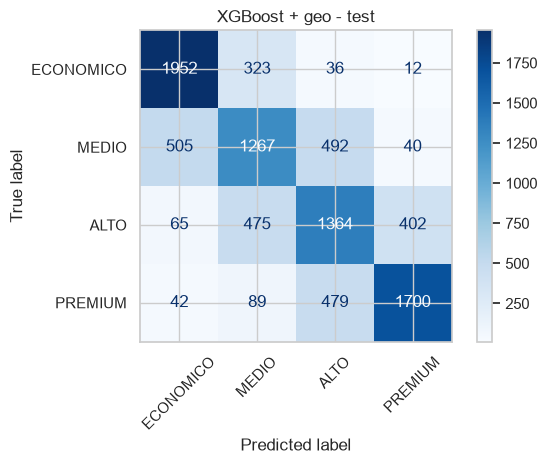

In [5]:
pred_test = decodificar_y(modelo.predict(X_test))
met_test = evaluar_modelo_ordinal(y_test, pred_test)
print({k: round(v, 4) for k, v in met_test.items() if k != 'matriz_confusion'})

ConfusionMatrixDisplay(
    met_test['matriz_confusion'], display_labels=CLASES
).plot(cmap='Blues', values_format='d')
plt.title('XGBoost + geo - test')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'xgboost_features_matriz_confusion.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

                                             variable  importancia
0                      cat__room_type_Entire home/apt     0.389102
1                                       num__bedrooms     0.064526
2                                   num__accommodates     0.043823
3                         cat__room_type_Private room     0.039854
4                                  num__bathrooms_num     0.038612
5                         num__distancia_hyde_park_km     0.027211
6                            num__distancia_centro_km     0.019050
7                    cat__property_type_Room in hotel     0.017464
8          cat__neighbourhood_cleansed_City of London     0.014386
9                            cat__host_is_superhost_t     0.010566
10     cat__property_type_Private room in rental unit     0.008747
11                                num__minimum_nights     0.008393
12                         cat__room_type_Shared room     0.008219
13  cat__neighbourhood_cleansed_Kensington and Che...     0.00

C:\Users\user\AppData\Local\Temp\ipykernel_3268\2098924362.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top, x='importancia', y='variable', palette='viridis')


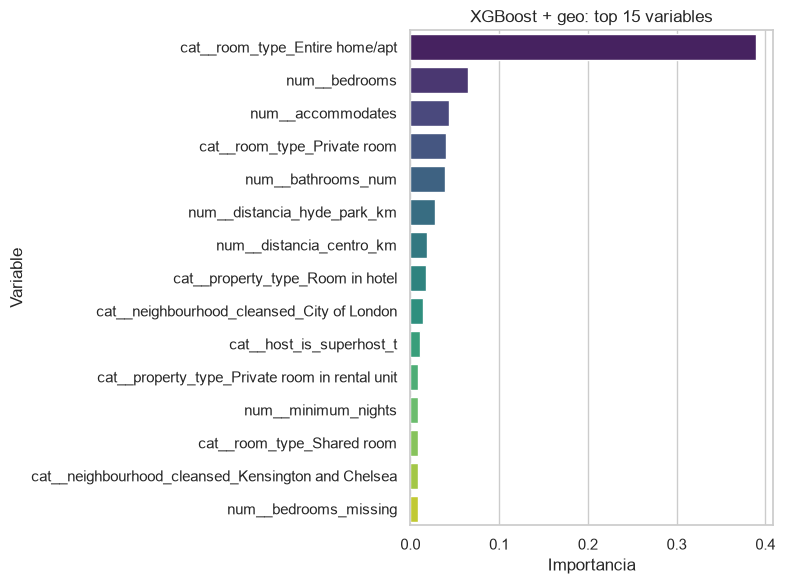

In [6]:
importancia = importancia_variables(modelo)
importancia.to_csv(
    REPORTS_DIR / 'xgboost_features_importancia.csv', index=False
)
print(importancia.head(15))

top = importancia.head(15)
plt.figure(figsize=(8, 6))
sns.barplot(data=top, x='importancia', y='variable', palette='viridis')
plt.title('XGBoost + geo: top 15 variables')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'xgboost_features_importancia.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

In [7]:
fila = metricas_a_fila(
    'xgboost_features',
    met_test,
    escenario='geo',
    **params,
)
pd.DataFrame([fila]).to_csv(
    REPORTS_DIR / 'xgboost_features_metricas.csv', index=False
)

ruta = guardar_modelo(modelo, 'xgboost_features')
print('Métricas y matriz guardadas en:', REPORTS_DIR)
print('Modelo guardado en:', ruta)

Métricas y matriz guardadas en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\reports
Modelo guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\models\xgboost_features.joblib


## Lectura de resultados

- Comparar `accuracy` y `f1_macro` con `reports/xgboost_metricas_test.csv`.
- Revisar si las distancias aparecen en el top de importancia. Aun si no aparecen, pueden aportar en interacción con `room_type`, `accommodates` o `neighbourhood_cleansed`.
- `accuracy_adjacent` y `qwk` permiten evaluar el costo ordinal de los errores.